<a href="https://colab.research.google.com/github/hasanjim-dev/ml-learning/blob/main/titanic/titanic_classification_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


Load Titanic dataset directly from seaborn

In [5]:

import seaborn as sns

data = sns.load_dataset('titanic')

data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [6]:
len(data)

891

In [7]:
len(data.columns)

15

In [8]:
(data.columns)

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [9]:
data['survived']

,survived
0,0
1,1
2,1
3,1
4,0
...,...
886,0
887,1
888,0
889,1


In [10]:
data['survived'].value_counts()

,count
survived,
0,549
1,342


In [11]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [12]:
data.isnull()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
887,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
888,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False
889,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [13]:
data.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


In [14]:
data['embarked']

,embarked
0,S
1,C
2,S
3,S
4,S
...,...
886,S
887,S
888,S
889,C


In [15]:
data['embarked'].value_counts()

,count
embarked,
S,644
C,168
Q,77


In [16]:
data["age"].median()

28.0

In [17]:
data['embarked'].mode()[0]

'S'

In [18]:
# [] -> Multiples
# Drop rows with too many missing values
data.drop(['deck'], axis=1, inplace=True, errors='ignore')

# Fill missing values
data['age'].fillna(data['age'].median(), inplace=True)
data['embarked'].fillna(data['embarked'].mode()[0], inplace=True)

# Drop less useful columns
data.drop(['embark_town', 'alive', 'class', 'who', 'adult_male'], axis=1, inplace=True)

/tmp/ipykernel_618/684280200.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['age'].fillna(data['age'].median(), inplace=True)
/tmp/ipykernel_618/684280200.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', tr

In [19]:
# Convert categorical variables to numeric
le = LabelEncoder()
data['sex'] = le.fit_transform(data['sex'])
data['embarked'] = le.fit_transform(data['embarked'])
data['alone'] = data['alone'].astype(int)

# Final check
data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
0,0,3,1,22.0,1,0,7.2500,2,0
1,1,1,0,38.0,1,0,71.2833,0,0
2,1,3,0,26.0,0,0,7.9250,2,1
3,1,1,0,35.0,1,0,53.1000,2,0
4,0,3,1,35.0,0,0,8.0500,2,1


In [20]:
data['sex']

,sex
0,1
1,0
2,0
3,0
4,1
...,...
886,1
887,0
888,0
889,1


In [21]:
data['embarked'].value_counts()

,count
embarked,
2,646
0,168
1,77


In [22]:
data['alone']

,alone
0,0
1,0
2,1
3,0
4,1
...,...
886,1
887,1
888,0
889,1


In [23]:
data['alone'].value_counts()

,count
alone,
1,537
0,354


In [24]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    int64  
 3   age       891 non-null    float64
 4   sibsp     891 non-null    int64  
 5   parch     891 non-null    int64  
 6   fare      891 non-null    float64
 7   embarked  891 non-null    int64  
 8   alone     891 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 62.8 KB


Survived-Count Plot

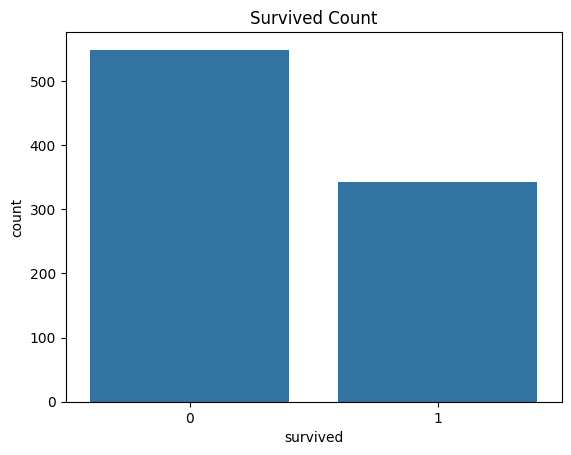

In [25]:
sns.countplot(x='survived', data=data)
plt.title('Survived Count')
plt.show()

Sex-Bar Plot(survival rate)

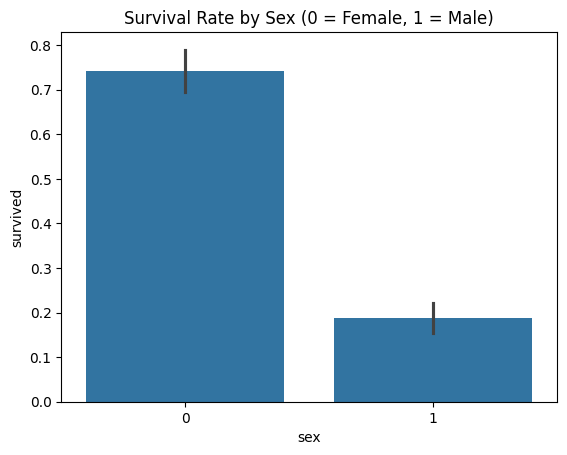

In [26]:
sns.barplot(x='sex', y='survived', data=data)
plt.title('Survival Rate by Sex (0 = Female, 1 = Male)')
plt.show()

Groupby-Survival Ratio

In [27]:
# Sex অনুযায়ী
print(data.groupby('sex')['survived'].mean())

# Pclass অনুযায়ী
print(data.groupby('pclass')['survived'].mean())

# Embarked অনুযায়ী
print(data.groupby('embarked')['survived'].mean())

sex
0    0.742038
1    0.188908
Name: survived, dtype: float64
pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64
embarked
0    0.553571
1    0.389610
2    0.339009
Name: survived, dtype: float64


Age Distribution-Histplot

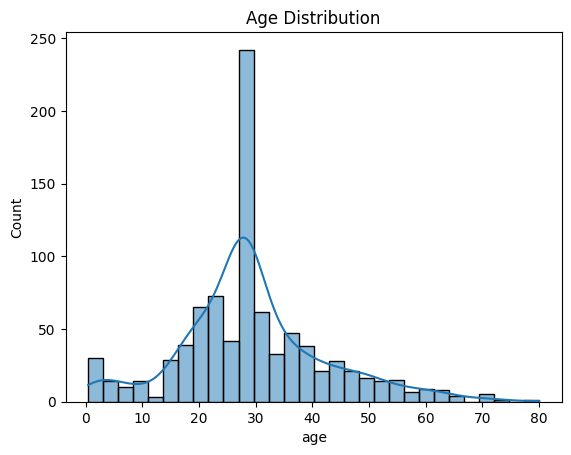

In [28]:
sns.histplot(data['age'], bins=30, kde=True)
plt.title('Age Distribution')
plt.show()

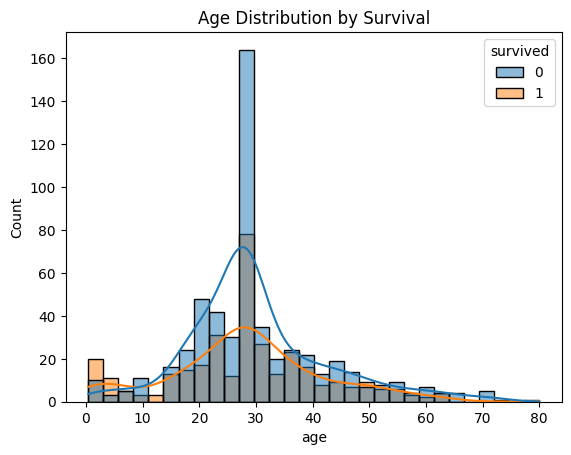

In [29]:
sns.histplot(data=data, x='age', hue='survived', bins=30, kde=True)
plt.title('Age Distribution by Survival')
plt.show()

In [30]:
data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
0,0,3,1,22.0,1,0,7.2500,2,0
1,1,1,0,38.0,1,0,71.2833,0,0
2,1,3,0,26.0,0,0,7.9250,2,1
3,1,1,0,35.0,1,0,53.1000,2,0
4,0,3,1,35.0,0,0,8.0500,2,1


Data Scaling

In [31]:
X = data.drop('survived', axis=1)
y = data['survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [32]:
print(X_train.shape)
print(X_test.shape)

(712, 8)
(179, 8)


In [33]:
print(len(y_train))
print(len(y_test))

712
179


Feature Scaling

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame for better readability (optional)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

In [35]:
X_train_scaled.head()

,pclass,sex,age,sibsp,parch,fare,embarked,alone
331,-1.614136,0.724310,1.253641,-0.470722,-0.479342,-0.078684,0.563525,0.812203
733,-0.400551,0.724310,-0.477284,-0.470722,-0.479342,-0.377145,0.563525,0.812203
382,0.813034,0.724310,0.215086,-0.470722,-0.479342,-0.474867,0.563525,0.812203
704,0.813034,0.724310,-0.246494,0.379923,-0.479342,-0.476230,0.563525,-1.231219
813,0.813034,-1.380624,-1.785093,2.931860,2.048742,-0.025249,0.563525,-1.231219


Logistic Regression

In [36]:
log_model = LogisticRegression(random_state=42)
log_model.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

Prediction

In [37]:
y_pred_log = log_model.predict(X_test_scaled)

Accuracy

In [38]:
acc_log = accuracy_score(y_test, y_pred_log)
print("Logistic Regression Accuracy:", acc_log)

Logistic Regression Accuracy: 0.7988826815642458


Classification Report

In [39]:
print(classification_report(y_test, y_pred_log))

              precision    recall  f1-score   support

           0       0.82      0.85      0.83       105
           1       0.77      0.73      0.75        74

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



Confusion Matrix

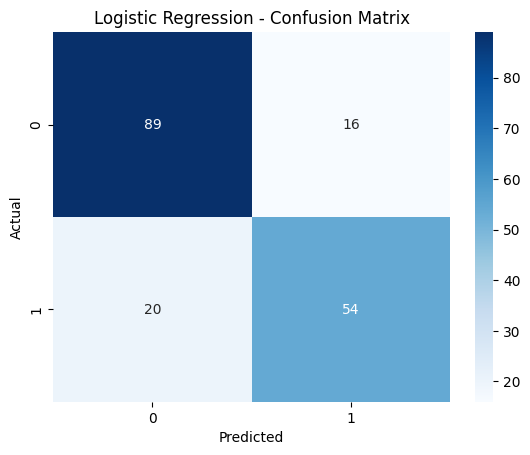

In [40]:
cm = confusion_matrix(y_test, y_pred_log)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Sigmoid

In [41]:
# প্রতিটা যাত্রীর বাঁচার probability
y_prob = log_model.predict_proba(X_test_scaled)[:, 1]
print(y_prob[:10])

[0.13383944 0.19935553 0.12263556 0.91933698 0.80868584 0.91919841
 0.64941369 0.1113766  0.72543715 0.93464957]


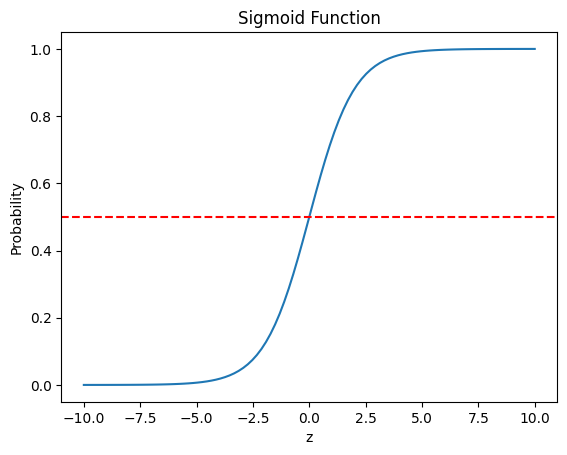

In [42]:
# Sigmoid curve আঁকা
z = np.linspace(-10, 10, 100)
sigmoid = 1 / (1 + np.exp(-z))

plt.plot(z, sigmoid)
plt.axhline(0.5, color='red', linestyle='--')
plt.title('Sigmoid Function')
plt.xlabel('z')
plt.ylabel('Probability')
plt.show()

KNN Model

In [43]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

KNeighborsClassifier()

Prediction

In [44]:
y_pred_knn = knn_model.predict(X_test_scaled)

Accuracy

In [45]:
acc_knn = accuracy_score(y_test, y_pred_knn)
print("KNN Accuracy:", acc_knn)

KNN Accuracy: 0.8044692737430168


Classification Report

In [46]:
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           0       0.82      0.85      0.84       105
           1       0.77      0.74      0.76        74

    accuracy                           0.80       179
   macro avg       0.80      0.80      0.80       179
weighted avg       0.80      0.80      0.80       179



Confusion Matrix

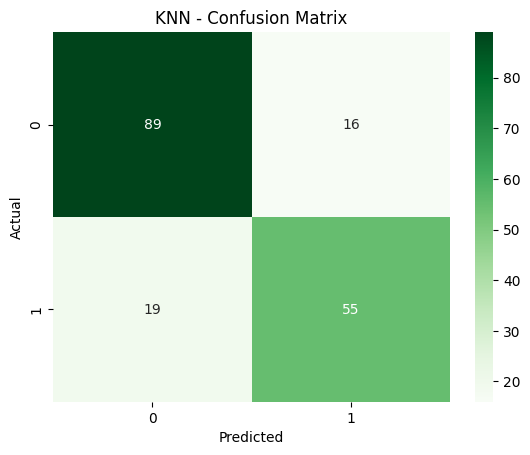

In [47]:
cm_knn = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Greens')
plt.title('KNN - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Choosing the right value of K

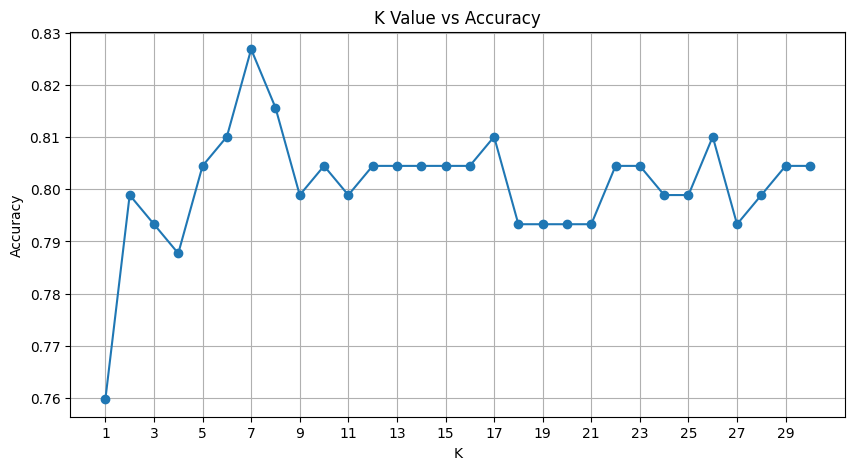

In [48]:
k_values = range(1, 31)
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    pred = knn.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, pred))

plt.figure(figsize=(10, 5))
plt.plot(k_values, accuracies, marker='o')
plt.title('K Value vs Accuracy')
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.xticks(range(1, 31, 2))
plt.grid(True)
plt.show()

In [49]:
# সবচেয়ে ভালো K কোনটা
best_k = k_values[accuracies.index(max(accuracies))]
print("Best K:", best_k)
print("Best Accuracy:", max(accuracies))

Best K: 7
Best Accuracy: 0.8268156424581006


Final KNN model (K = 7)

In [50]:
knn_best = KNeighborsClassifier(n_neighbors=7)
knn_best.fit(X_train_scaled, y_train)

y_pred_knn_best = knn_best.predict(X_test_scaled)
acc_knn_best = accuracy_score(y_test, y_pred_knn_best)
print("KNN (K=7) Accuracy:", acc_knn_best)

KNN (K=7) Accuracy: 0.8268156424581006


In [51]:
print(classification_report(y_test, y_pred_knn_best))

              precision    recall  f1-score   support

           0       0.82      0.90      0.86       105
           1       0.83      0.73      0.78        74

    accuracy                           0.83       179
   macro avg       0.83      0.81      0.82       179
weighted avg       0.83      0.83      0.82       179



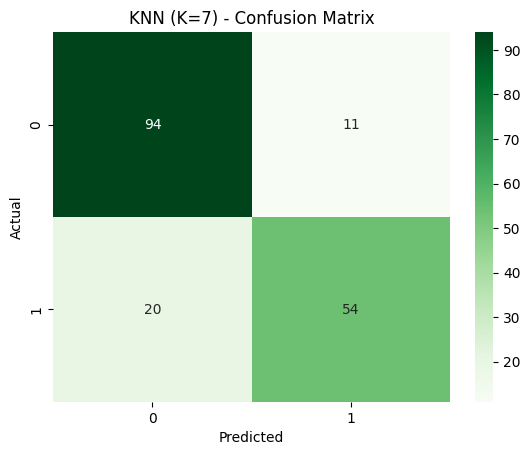

In [52]:
cm_knn_best = confusion_matrix(y_test, y_pred_knn_best)
sns.heatmap(cm_knn_best, annot=True, fmt='d', cmap='Greens')
plt.title('KNN (K=7) - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Logistic Regression vs KNN - accuracy

In [53]:
print("Logistic Regression:", acc_log)
print("KNN (K=7):", acc_knn_best)

Logistic Regression: 0.7988826815642458
KNN (K=7): 0.8268156424581006


Decision Tree Model (Gini)

In [54]:
dt_gini = DecisionTreeClassifier(criterion='gini', random_state=42)
dt_gini.fit(X_train, y_train)

y_pred_dt = dt_gini.predict(X_test)
acc_dt = accuracy_score(y_test, y_pred_dt)
print("Decision Tree (Gini) Accuracy:", acc_dt)

Decision Tree (Gini) Accuracy: 0.7821229050279329


In [55]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.82      0.80      0.81       105
           1       0.73      0.76      0.74        74

    accuracy                           0.78       179
   macro avg       0.78      0.78      0.78       179
weighted avg       0.78      0.78      0.78       179



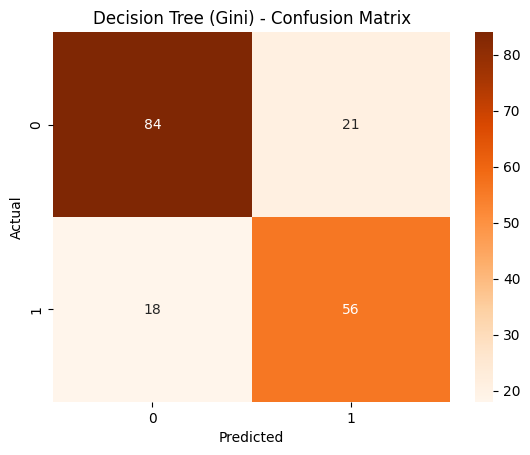

In [56]:
cm_dt = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Oranges')
plt.title('Decision Tree (Gini) - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Splitting Criteria: Gini vs Entropy

In [57]:
dt_entropy = DecisionTreeClassifier(criterion='entropy', random_state=42)
dt_entropy.fit(X_train, y_train)

y_pred_entropy = dt_entropy.predict(X_test)
acc_entropy = accuracy_score(y_test, y_pred_entropy)

print("Gini Accuracy:", acc_dt)
print("Entropy Accuracy:", acc_entropy)

Gini Accuracy: 0.7821229050279329
Entropy Accuracy: 0.776536312849162


plot_tree

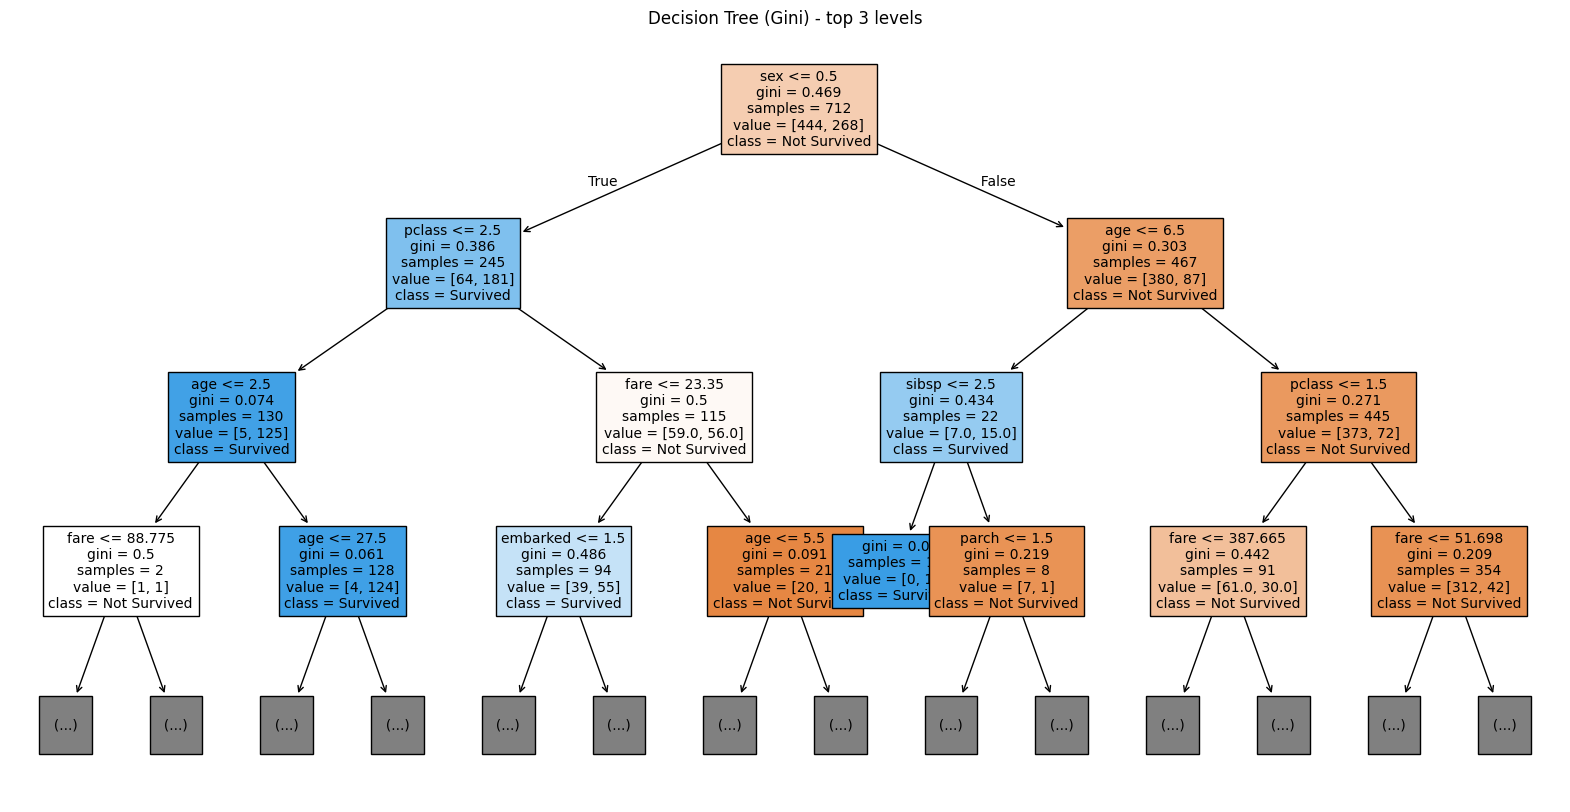

In [58]:
plt.figure(figsize=(20, 10))
plot_tree(dt_gini, feature_names=X.columns, class_names=['Not Survived', 'Survived'],
          filled=True, max_depth=3, fontsize=10)
plt.title('Decision Tree (Gini) - top 3 levels')
plt.show()

Overfitting

In [59]:
print("Train Accuracy:", dt_gini.score(X_train, y_train))
print("Test Accuracy:", dt_gini.score(X_test, y_test))

Train Accuracy: 0.9789325842696629
Test Accuracy: 0.7821229050279329


Pruning (max_depth, overfitting(-)  )

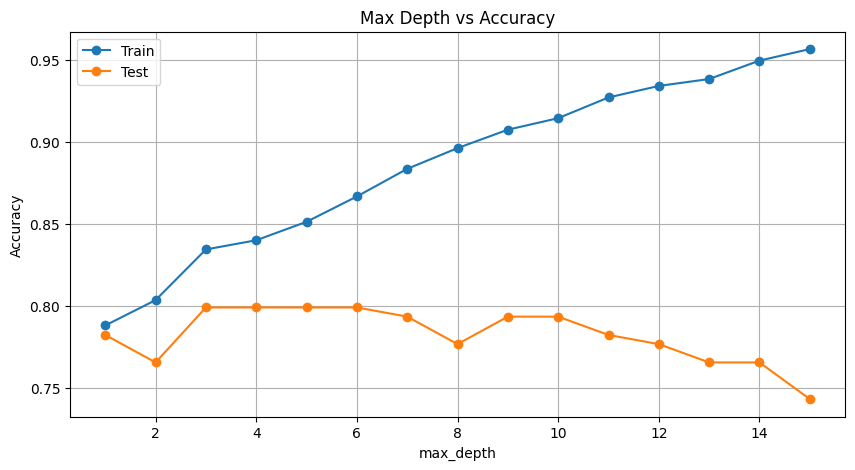

In [60]:
depths = range(1, 16)
train_scores = []
test_scores = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt.fit(X_train, y_train)
    train_scores.append(dt.score(X_train, y_train))
    test_scores.append(dt.score(X_test, y_test))

plt.figure(figsize=(10, 5))
plt.plot(depths, train_scores, marker='o', label='Train')
plt.plot(depths, test_scores, marker='o', label='Test')
plt.title('Max Depth vs Accuracy')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [61]:
best_depth = depths[test_scores.index(max(test_scores))]
print("Best max_depth:", best_depth)
print("Best Test Accuracy:", max(test_scores))

Best max_depth: 3
Best Test Accuracy: 0.7988826815642458


Pruned Decision Tree (BY best depth)

In [63]:
dt_pruned = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
dt_pruned.fit(X_train, y_train)

y_pred_pruned = dt_pruned.predict(X_test)
acc_pruned = accuracy_score(y_test, y_pred_pruned)
print("Pruned Decision Tree Accuracy:", acc_pruned)

Pruned Decision Tree Accuracy: 0.7988826815642458


Pruned Tree-(plot_tree)

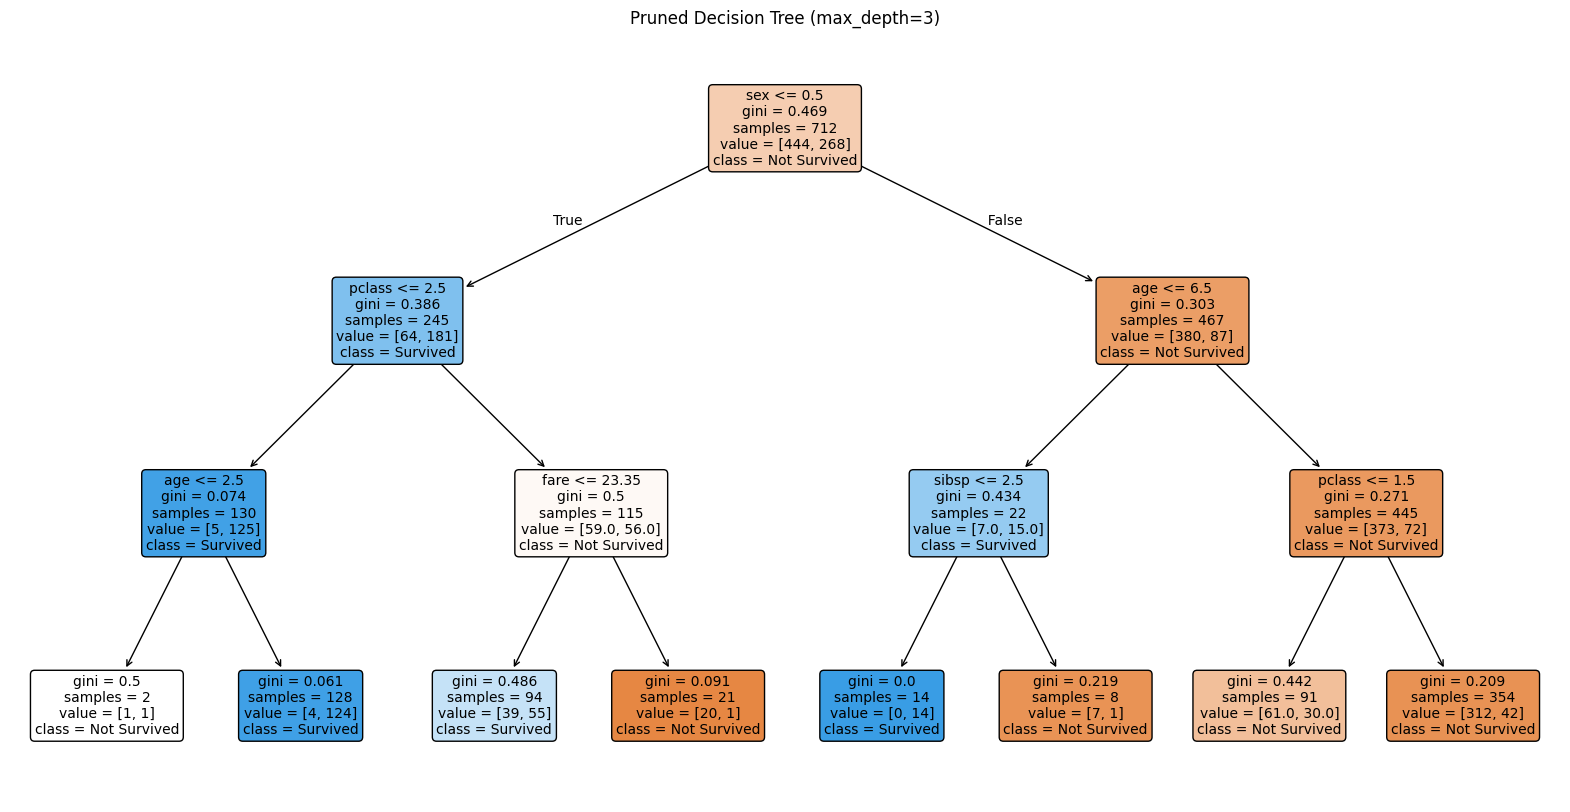

In [64]:
plt.figure(figsize=(20, 10))
plot_tree(dt_pruned, feature_names=X.columns, class_names=['Not Survived', 'Survived'],
          filled=True, rounded=True, fontsize=10)
plt.title(f'Pruned Decision Tree (max_depth={best_depth})')
plt.show()

(unpruned) tree- difference

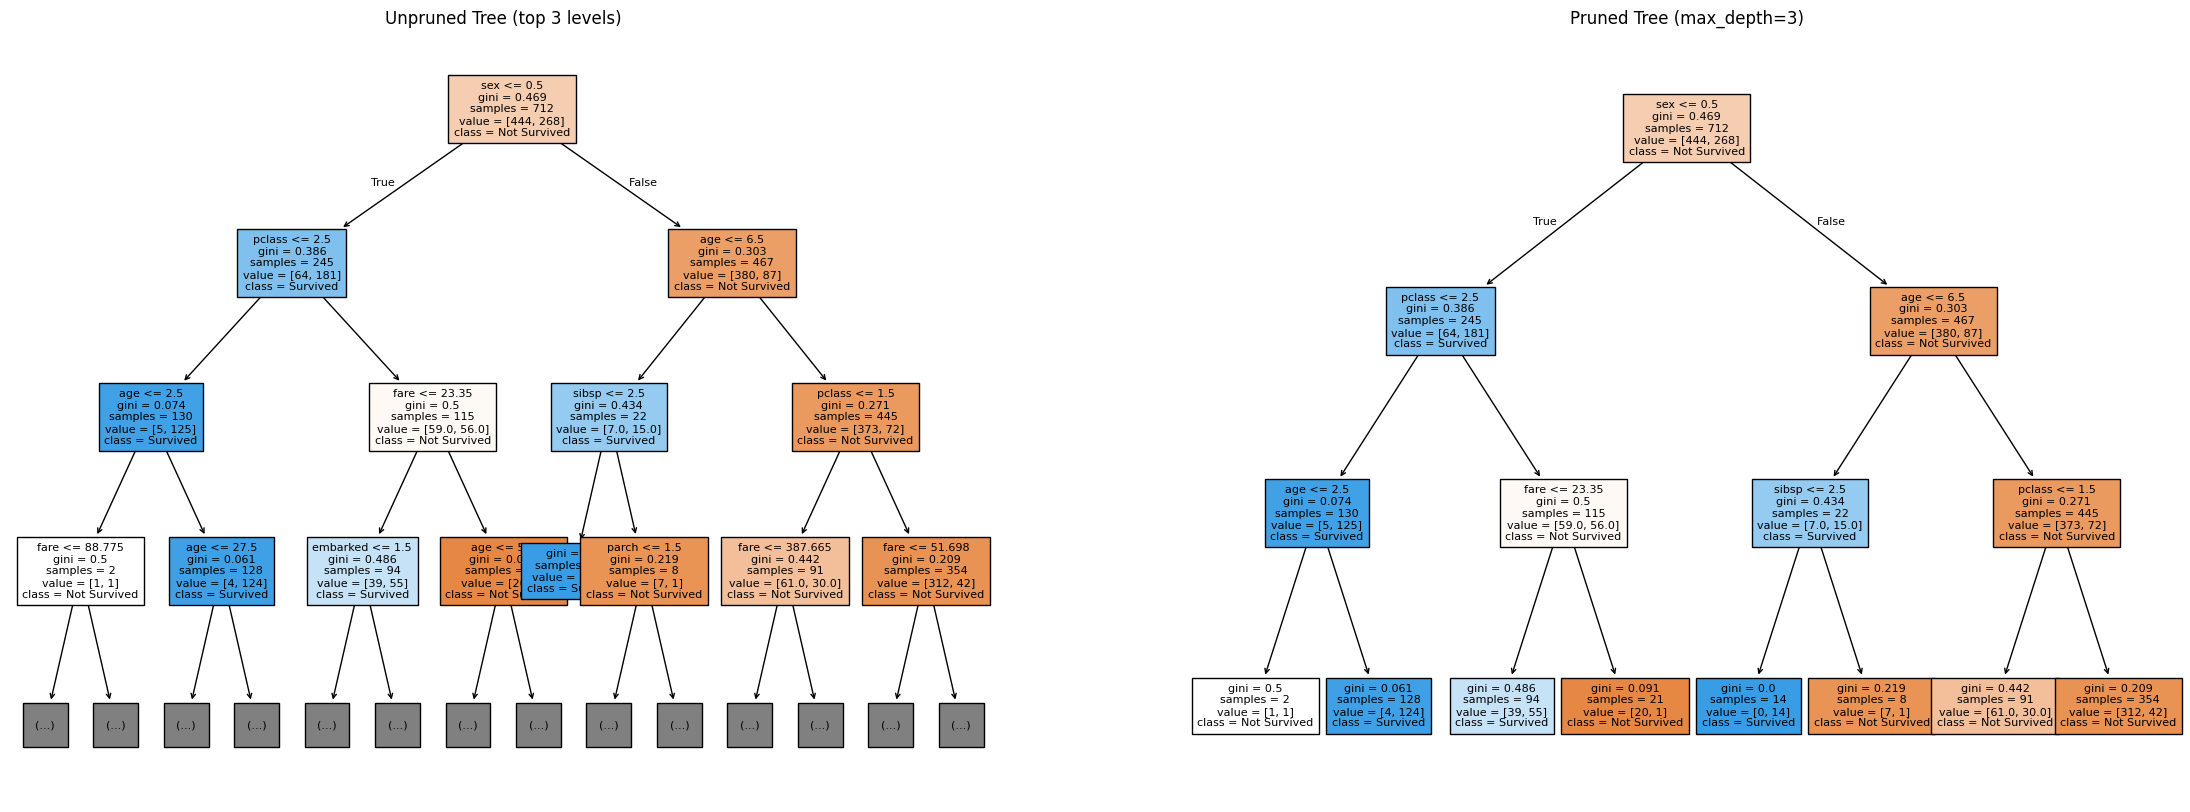

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(28, 10))

plot_tree(dt_gini, feature_names=X.columns, class_names=['Not Survived', 'Survived'],
          filled=True, max_depth=3, fontsize=8, ax=axes[0])
axes[0].set_title('Unpruned Tree (top 3 levels)')

plot_tree(dt_pruned, feature_names=X.columns, class_names=['Not Survived', 'Survived'],
          filled=True, fontsize=8, ax=axes[1])
axes[1].set_title(f'Pruned Tree (max_depth={best_depth})')

plt.show()

**Accuracy of 3 Model**

In [66]:
results = {
    'Logistic Regression': acc_log,
    'KNN (K=7)': acc_knn_best,
    'Decision Tree (Pruned)': acc_pruned
}

for name, acc in results.items():
    print(f"{name}: {acc:.4f}")

Logistic Regression: 0.7989
KNN (K=7): 0.8268
Decision Tree (Pruned): 0.7989


Table

In [67]:
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy': list(results.values())
})
comparison_df = comparison_df.sort_values(by='Accuracy', ascending=False).reset_index(drop=True)
comparison_df

,Model,Accuracy
0,KNN (K=7),0.826816
1,Logistic Regression,0.798883
2,Decision Tree (Pruned),0.798883


Bar Chart

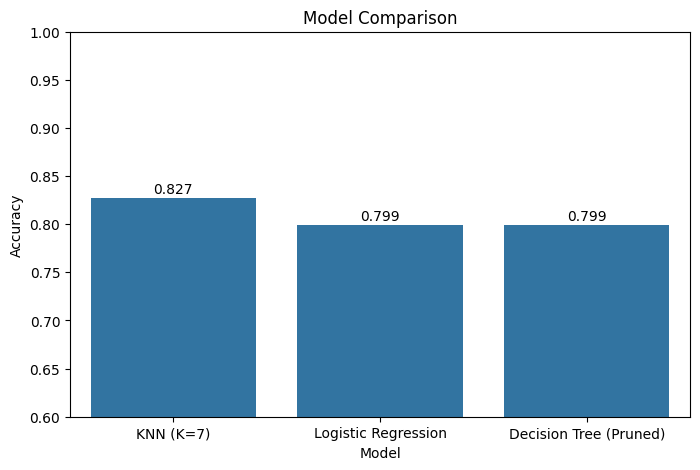

In [68]:
plt.figure(figsize=(8, 5))
sns.barplot(x='Model', y='Accuracy', data=comparison_df)
plt.title('Model Comparison')
plt.ylim(0.6, 1.0)
for i, v in enumerate(comparison_df['Accuracy']):
    plt.text(i, v + 0.005, f"{v:.3f}", ha='center')
plt.show()

**Precision, Recall, F1 of 3 Model**

In [69]:
from sklearn.metrics import precision_score, recall_score, f1_score

predictions = {
    'Logistic Regression': y_pred_log,
    'KNN (K=7)': y_pred_knn_best,
    'Decision Tree (Pruned)': y_pred_pruned
}

rows = []
for name, pred in predictions.items():
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-score': f1_score(y_test, pred)
    })

metrics_df = pd.DataFrame(rows)
metrics_df

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.798883,0.771429,0.729730,0.750000
1,KNN (K=7),0.826816,0.830769,0.729730,0.776978
2,Decision Tree (Pruned),0.798883,0.796875,0.689189,0.739130


**Confusion Matrix of 3 Model**

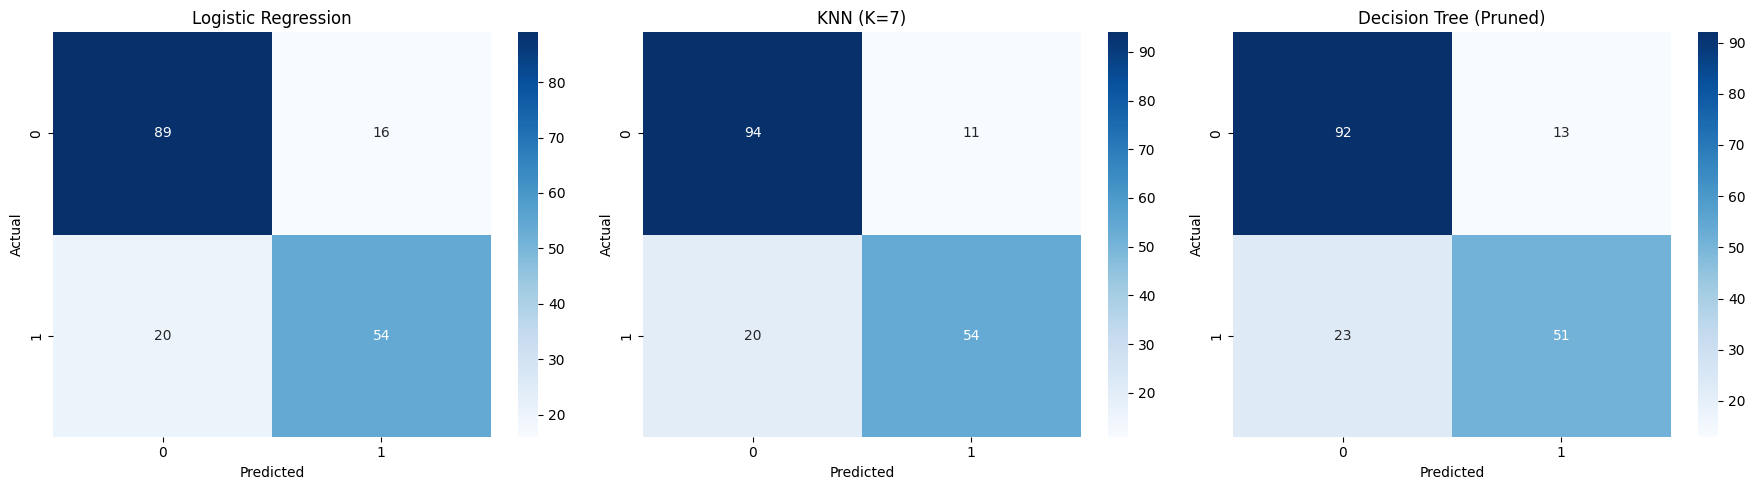

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, predictions.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

**Feature Importance (Using Decision Tree)**

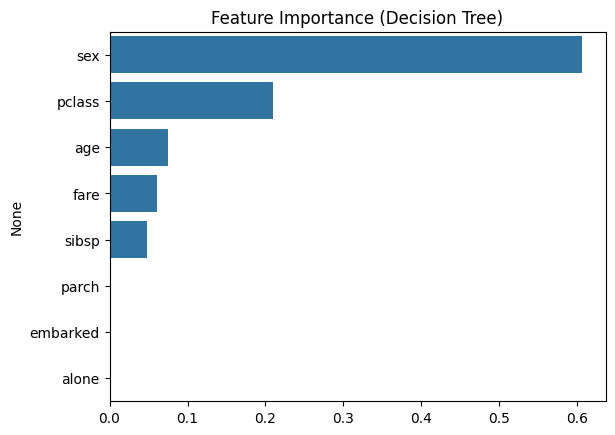

In [71]:
importances = pd.Series(dt_pruned.feature_importances_, index=X.columns).sort_values(ascending=False)
sns.barplot(x=importances.values, y=importances.index)
plt.title('Feature Importance (Decision Tree)')
plt.show()

Random Forest Model

In [72]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

Prediction ও Accuracy

In [73]:
y_pred_rf = rf_model.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)
print("Random Forest Accuracy:", acc_rf)

Random Forest Accuracy: 0.8268156424581006


Classification Report

In [74]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.84      0.87      0.85       105
           1       0.80      0.77      0.79        74

    accuracy                           0.83       179
   macro avg       0.82      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179



Confusion Matrix

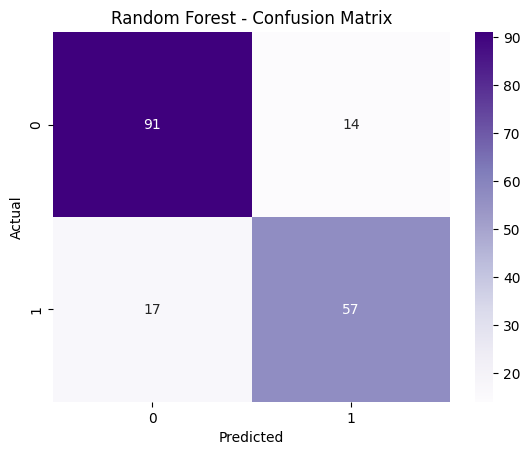

In [75]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Purples')
plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Overfitting check

In [76]:
print("Train Accuracy:", rf_model.score(X_train, y_train))
print("Test Accuracy:", rf_model.score(X_test, y_test))

Train Accuracy: 0.9789325842696629
Test Accuracy: 0.8268156424581006


Feature Importance

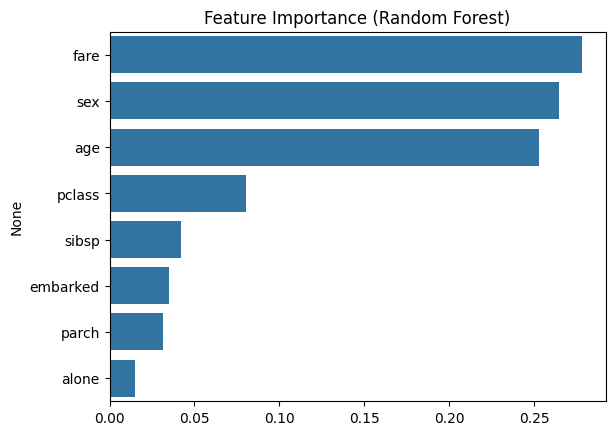

In [77]:
rf_importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
sns.barplot(x=rf_importances.values, y=rf_importances.index)
plt.title('Feature Importance (Random Forest)')
plt.show()

n_estimators (গাছের সংখ্যা) বদলালে কী হয়

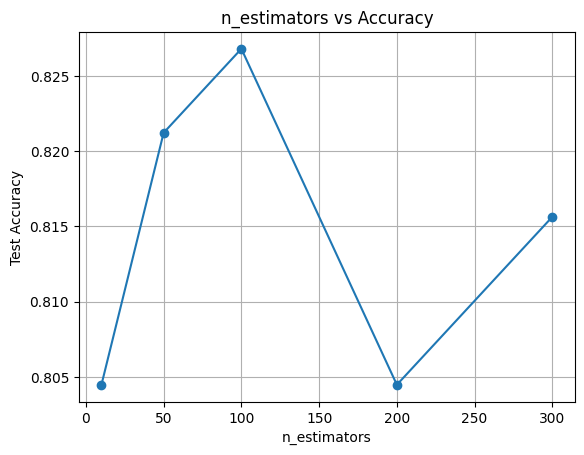

In [78]:
n_values = [10, 50, 100, 200, 300]
rf_scores = []

for n in n_values:
    rf = RandomForestClassifier(n_estimators=n, random_state=42)
    rf.fit(X_train, y_train)
    rf_scores.append(rf.score(X_test, y_test))

plt.plot(n_values, rf_scores, marker='o')
plt.title('n_estimators vs Accuracy')
plt.xlabel('n_estimators')
plt.ylabel('Test Accuracy')
plt.grid(True)
plt.show()

Final Result of all Model

In [79]:
final_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN (K=7)', 'Decision Tree (Pruned)', 'Random Forest'],
    'Accuracy': [acc_log, acc_knn_best, acc_pruned, acc_rf]
}).sort_values(by='Accuracy', ascending=False).reset_index(drop=True)

final_results

,Model,Accuracy
0,KNN (K=7),0.826816
1,Random Forest,0.826816
2,Logistic Regression,0.798883
3,Decision Tree (Pruned),0.798883
